### Torkelnde Yamyams – Lösung Schritt für Schritt

*34. Bundeswettbewerb Informatik (2015/2016), 2. Runde, Aufgabe 3*

In einer aus quadratischen Feldern bestehenden Welt bewegt sich ein Yamyam auf folgende Weise: Hat er sich einmal zufällig für eine der
vier Himmelsrichtungen entschieden, so fährt er in dieser Richtung entlang, bis er auf ein Hindernis stößt. Dann setzt er seine Fahrt in
eine zufällige freie Himmelsrichtung fort. Es gibt in dieser Welt Ausgänge. Es ist wünschenswert, dass ein Yamyam auf seiner
zufallsgesteuerten Reise sicher zu einem Ausgang findet.

Wir nennen ein Feld *sicher*, wenn ein Yamyam von diesem aus irgendwann einen Ausgang erreicht, egal wie die zufälligen
Richtungsänderungen ausfallen und wie lange die Fahrt dauert. Mathematisch ausgedrückt ist ein Feld sicher, wenn ein Yamyam von dort mit
Wahrscheinlichkeit 1 einen Ausgang erreicht.

*(Bild: eine kleine Welt aus 12 × 8 Feldern, das Beispiel `yamyams0.txt`, mit Mauern, drei dunkelgrünen Ausgängen und hellgrünen
sicheren Feldern.)*

Im linken Beispiel sind die sicheren Felder hellgrün und die Ausgänge dunkelgrün eingezeichnet. Das oberste, linke hellgrüne Feld ist
beispielsweise sicher: Ein Yamyam könnte zwar zunächst nach rechts und dann viele Male abwechselnd nach links und nach rechts fahren. Aber
irgendwann wird er auch einmal den Weg nach unten wählen, wenn er an eine der beiden Wände stößt, und dann direkt einen Ausgang erreichen.

#### Aufgabe

Schreibe ein Programm, das eine Beschreibung solch einer Welt einlesen kann und dann die sicheren Felder bestimmt. Lasse dein Programm
auf den Beispielen laufen, die du auf der BWINF-Webseite findest. Diese Beispiele enthalten auch folgende Welt:

*(Bild: eine Welt aus 24 × 24 Feldern mit vielen Mauerstücken und vier Ausgängen, das Beispiel `yamyams5.txt`.)*

Bei dieser Welt ist es wahrscheinlich zu mühsam, die sicheren Felder ohne Computerhilfe zu bestimmen.

#### Beispieldaten

In den Dateien `yamyams0.txt` bis `yamyams6.txt` steht `#` für eine Mauer, `E` für einen Ausgang und ein Leerzeichen für ein freies Feld;
`A3_beispiele.pdf` zeigt die Welten als Bilder. Die Datei `yamyams6.txt` ist auf der BWINF-Webseite **leer** (0 Bytes). Wir haben die
Welt deshalb aus dem Bild in `A3_beispiele.pdf` abgelesen und in `eigene_testdaten/yamyams6.txt` gespeichert. Die Lösungshinweise zeigen
dieselbe Welt.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Gerichteter Graph:** Jedes freie Feld und jeder Ausgang ist ein Knoten. Ein Pfeil von A nach B heißt: Ein Yamyam, der auf A steht,
  kann mit einer Fahrt nach B kommen. Wir speichern zu jedem Feld die Liste seiner **Ziele** (wohin seine Pfeile zeigen) und für
  Version 2 auch seiner **Vorgänger** (woher Pfeile zu ihm kommen).
- **Tiefensuche mit einem Stapel:** findet alle Felder, die man von einem oder mehreren Startfeldern aus über Pfeile erreicht.
  Mit den Vorgängern statt der Ziele sucht man **rückwärts**: Welche Felder können die Startfelder erreichen?
- **Ein bisschen Wahrscheinlichkeit:** Ein Ereignis, das bei jedem Versuch mindestens mit einer festen Wahrscheinlichkeit q > 0
  eintritt, tritt auf lange Sicht mit Wahrscheinlichkeit 1 ein, denn (1 − q)ᵏ wird beliebig klein.
- Für Neugierige: ein **lineares Gleichungssystem** für die genauen Wahrscheinlichkeiten (Abschnitt 3.2 der Lösungshinweise).

**Nützliche Funktionen und Bibliotheken**
- Ein Feld speichern wir als Tupel `(zeile, spalte)`. Tupel können Schlüssel eines Dictionarys und Elemente einer Menge sein.
- Mengen (`set`): `a & b` sind die gemeinsamen Elemente, `a - b` die Elemente von `a`, die nicht in `b` sind.
- `random.Random(zahl)` mit `choice(liste)`: zufällige Fahrten, bei gleicher Zahl immer dieselben (für die Probe durch Simulation).
- `matplotlib`: `imshow` zeichnet eine Tabelle von Zahlen als farbiges Bild.
- Für Neugierige: `numpy.linalg.solve` löst ein lineares Gleichungssystem.

## Die Idee in Worten

1. **Fahrten.** Von jedem freien Feld aus kann der Yamyam in jede Richtung fahren, in der nicht direkt eine Mauer steht. Er fährt, bis
   vor ihm eine Mauer ist. Fährt er unterwegs über einen Ausgang, ist er angekommen (so legen es die Lösungshinweise aus; im Beispiel
   `yamyams4.txt` liegt der einzige Ausgang mitten im Raum, dort könnte er sonst nie stehen bleiben). Ein Yamyam, der auf einem Ausgang
   startet, ist sofort angekommen.
2. **Wann ist ein Feld nicht sicher?** Wenn der Yamyam von dort aus ein Feld erreichen kann, von dem aus **kein** Ausgang mehr erreichbar
   ist. Solche Felder nennen wir wie die Lösungshinweise **rot**. Die Fahrt dorthin hat eine Wahrscheinlichkeit größer als 0, und von dort
   kommt er nie wieder heraus.
3. **Wann ist ein Feld sicher?** Wenn jedes Feld, das der Yamyam von dort aus erreichen kann, noch einen Ausgang erreichen kann. Dann
   hat er von jedem Feld aus, auf dem er gerade steht, eine kleine, aber feste Chance, in den nächsten Fahrten einen Ausgang zu
   erreichen. Dass er diese Chance unendlich oft verpasst, hat die Wahrscheinlichkeit 0.
4. **Version 1:** genau nach dieser Beschreibung: von jedem Feld aus alles Erreichbare suchen.
5. **Version 2** (Flood-Fill der Lösungshinweise): zweimal **rückwärts** suchen. Erst von den Ausgängen aus: Alle Felder, die einen
   Ausgang erreichen können, sind **blau**, der Rest ist **rot**. Dann von den roten Feldern aus: Alle blauen Felder, die ein rotes
   erreichen können, sind **gelb**, die übrigen sind **grün** – das sind die sicheren Felder.
6. **Proben:** Ergebnisse von Version 1 und 2 vergleichen, Yamyams zufällig fahren lassen und die Bilder der Lösungshinweise ansehen.
7. **Für Neugierige** und **zum Schluss:** die genauen Wahrscheinlichkeiten, große Zufallswelten und ein MiniZinc-Modell.

## Schritt 1: Einlesen

Eine Welt speichern wir als Liste von Zeichenketten, eine je Zeile. Das Feld in Zeile `z` und Spalte `s` ist dann `welt[z][s]`; gezählt
wird wie üblich ab 0, oben links. Beim Einlesen entfernen wir nur das Zeilenende, **nicht** die Leerzeichen, denn sie sind freie Felder.

In [ ]:
NAMEN = ['yamyams0', 'yamyams1', 'yamyams2', 'yamyams3', 'yamyams4', 'yamyams5', 'yamyams6']


def dateiname(name):
    if name == 'yamyams6':                  # auf der BWINF-Seite leer, aus dem Bild abgelesen
        return 'eigene_testdaten/yamyams6.txt'
    return 'beispieldaten/' + name + '.txt'


def lies_welt(dateiname):
    welt = []
    with open(dateiname, encoding='utf-8') as datei:
        for zeile in datei:
            zeile = zeile.rstrip('\r\n')    # nur das Zeilenende weg, Leerzeichen bleiben
            if zeile != '':
                welt.append(zeile)
    return welt


welten = {}
for name in NAMEN:
    welt = lies_welt(dateiname(name))
    welten[name] = welt
    frei = 0
    ausgaenge = 0
    for zeile in welt:
        frei = frei + zeile.count(' ')
        ausgaenge = ausgaenge + zeile.count('E')
    print(f'{name}: {len(welt[0]):2} x {len(welt):2} Felder, {frei:3} frei, {ausgaenge} Ausgänge')
print()
print('\n'.join(welten['yamyams0']))

yamyams0: 12 x  8 Felder,  46 frei, 3 Ausgänge
yamyams1: 24 x 13 Felder, 205 frei, 3 Ausgänge
yamyams2: 51 x 25 Felder, 596 frei, 3 Ausgänge
yamyams3: 19 x 15 Felder, 202 frei, 1 Ausgänge
yamyams4: 19 x 15 Felder, 182 frei, 1 Ausgänge
yamyams5: 24 x 24 Felder, 386 frei, 4 Ausgänge
yamyams6:  6 x 16 Felder,  44 frei, 1 Ausgänge

############
# #      # #
#   ##     #
#   #   E# #
#       ## #
#          #
# #E    E###
############


`yamyams0` ist die Welt vom Aufgabenblatt, `yamyams5` die große Welt darunter. Alle Welten sind ringsum von Mauern umgeben; das dürfen wir
laut Lösungshinweisen voraussetzen. Deshalb fällt ein Yamyam nie aus der Welt.

## Schritt 2: Fahrten

`fahrt` lässt den Yamyam von `(z, s)` in die Richtung `(dz, ds)` fahren, bis vor ihm eine Mauer ist oder er auf einem Ausgang steht.
`ziele_berechnen` gibt ein Dictionary zurück: Zu jedem freien Feld und jedem Ausgang gehört die Liste der Felder, die der Yamyam mit einer
Fahrt erreicht. Ein Ausgang hat keine Ziele, denn dort ist die Reise zu Ende.

In eine Richtung, in der direkt eine Mauer steht, fährt der Yamyam nicht. Hätte er sich für sie entschieden, würde er gleich eine neue
Richtung wählen; das ist dasselbe, wie gleich unter den freien Richtungen zu wählen.

In [ ]:
RICHTUNGEN = [(-1, 0), (0, 1), (1, 0), (0, -1)]     # Norden, Osten, Süden, Westen als (dz, ds)


def fahrt(welt, z, s, dz, ds):
    """Fährt von (z, s) in Richtung (dz, ds) bis vor eine Mauer oder auf einen Ausgang."""
    while welt[z + dz][s + ds] != '#':
        z = z + dz
        s = s + ds
        if welt[z][s] == 'E':               # über einen Ausgang fahren reicht
            break
    return (z, s)


def ziele_berechnen(welt):
    ziele = {}
    for z in range(len(welt)):
        for s in range(len(welt[z])):
            if welt[z][s] == 'E':
                ziele[(z, s)] = []          # am Ausgang ist die Reise zu Ende
            elif welt[z][s] == ' ':
                liste = []
                for dz, ds in RICHTUNGEN:
                    if welt[z + dz][s + ds] != '#':          # nur freie Richtungen
                        liste.append(fahrt(welt, z, s, dz, ds))
                ziele[(z, s)] = liste
    return ziele


def ist_ausgang(welt, feld):
    return welt[feld[0]][feld[1]] == 'E'


ziele0 = ziele_berechnen(welten['yamyams0'])
print('Ziele von (1, 3):', ziele0[(1, 3)])
print('Ziele von (1, 8):', ziele0[(1, 8)])
print('Ziele von (5, 1):', ziele0[(5, 1)])

Ziele von (1, 3): [(1, 8), (6, 3)]
Ziele von (1, 8): [(3, 8), (1, 3)]
Ziele von (5, 1): [(1, 1), (5, 10), (6, 1)]


Das Feld `(1, 3)` ist das oberste, linke hellgrüne Feld vom Aufgabenblatt. Nach rechts fährt der Yamyam bis `(1, 8)`, von dort nach
links zurück oder nach unten bis `(3, 8)`, einem Ausgang. Nach unten kommt er von `(1, 3)` aus direkt auf den Ausgang `(6, 3)`, genau wie
es die Aufgabe beschreibt. Das Feld `(5, 1)` in der linken Spalte kann nur nach oben, nach rechts oder nach unten.

## Schritt 3: Was erreicht ein Yamyam von einem Feld aus?

`erreichbar(starts, pfeile)` sucht mit einem Stapel alle Felder, die man von den Startfeldern aus über die Pfeile erreicht (die
Startfelder eingeschlossen). `pfeile` ist ein Dictionary wie `ziele`. Später geben wir der Funktion auch die Vorgänger statt der Ziele.

`als_text` zeichnet eine Welt wieder als Text. Das Dictionary `markierung` sagt, welcher Buchstabe auf welchem freien Feld stehen soll;
Mauern und Ausgänge bleiben, wie sie sind.

In [ ]:
def erreichbar(starts, pfeile):
    """Alle Felder, die man von den Startfeldern aus über die Pfeile erreicht (Startfelder eingeschlossen)."""
    gefunden = set(starts)
    stapel = list(starts)
    while len(stapel) > 0:
        feld = stapel.pop()
        for nachbar in pfeile[feld]:
            if nachbar not in gefunden:
                gefunden.add(nachbar)
                stapel.append(nachbar)
    return gefunden


def als_text(welt, markierung):
    zeilen = []
    for z in range(len(welt)):
        zeile = ''
        for s in range(len(welt[z])):
            if welt[z][s] == ' ' and (z, s) in markierung:
                zeile = zeile + markierung[(z, s)]
            else:
                zeile = zeile + welt[z][s]
        zeilen.append(zeile)
    return '\n'.join(zeilen)


welt0 = welten['yamyams0']
von_5_1 = erreichbar([(5, 1)], ziele0)
markierung = {}
for feld in von_5_1:
    markierung[feld] = '*'
print(len(von_5_1), 'Felder sind von (5, 1) aus erreichbar:')
print(als_text(welt0, markierung))

5 Felder sind von (5, 1) aus erreichbar:
############
#*#      #*#
#   ##     #
#   #   E# #
#       ## #
#*        *#
#*#E    E###
############


Von `(5, 1)` aus erreicht der Yamyam nur drei Felder der linken und zwei der rechten Spalte, aber keinen Ausgang. Er torkelt für
immer zwischen ihnen hin und her. Solche Felder sind die **roten** Felder.

## Schritt 4: Version 1 – für jedes Feld vorwärts suchen

Genau nach der Idee:
1. Für jedes Feld suchen wir alles, was von ihm aus erreichbar ist.
2. **Rot** ist ein Feld, wenn darunter kein Ausgang ist.
3. **Sicher** ist ein Feld, wenn darunter kein rotes Feld ist. Ausgänge sind damit auch sicher (sie erreichen nur sich selbst).

`besucht` zählt, wie viele Felder die Suchen zusammen gefunden haben; damit vergleichen wir später den Aufwand.

In [ ]:
def sichere_felder_v1(welt):
    ziele = ziele_berechnen(welt)
    von = {}
    besucht = 0
    for feld in ziele:
        von[feld] = erreichbar([feld], ziele)
        besucht = besucht + len(von[feld])
    rot = set()
    for feld in ziele:
        hat_ausgang = False
        for f in von[feld]:
            if ist_ausgang(welt, f):
                hat_ausgang = True
        if not hat_ausgang:
            rot.add(feld)
    sicher = set()
    for feld in ziele:
        if len(von[feld] & rot) == 0:       # kein rotes Feld erreichbar
            sicher.add(feld)
    return sicher, rot, besucht


def markiere(felder, buchstabe):
    markierung = {}
    for feld in felder:
        markierung[feld] = buchstabe
    return markierung


sicher0, rot0, besucht0 = sichere_felder_v1(welt0)
print(f'{len(sicher0)} sichere Felder (mit Ausgängen), {len(rot0)} rote, {besucht0} Felder besucht')
print(als_text(welt0, markiere(sicher0, 'S')))

15 sichere Felder (mit Ausgängen), 8 rote, 443 Felder besucht
############
# #SSSSSS# #
#   ##     #
#   #SSSE# #
#       ## #
#          #
# #E SSSE###
############


Die sicheren Felder (`S`) sind genau die hellgrünen Felder auf dem Aufgabenblatt: sechs Felder oben, drei links neben dem Ausgang in der
Mitte und drei zwischen den beiden unteren Ausgängen.

### Warum ist das richtig?

- **Rote Felder erreichbar ⇒ nicht sicher.** Gibt es einen Weg zu einem roten Feld, dann fährt der Yamyam ihn mit einer
  Wahrscheinlichkeit größer als 0 (bei höchstens 4 Richtungen hat jede Fahrt mindestens die Wahrscheinlichkeit 1/4). Vom roten Feld aus
  erreicht er nie einen Ausgang. Die Wahrscheinlichkeit, anzukommen, ist also kleiner als 1.
- **Kein rotes Feld erreichbar ⇒ sicher.** Es gibt N Felder. Von jedem Feld, auf dem der Yamyam unterwegs stehen kann, führt ein Weg mit
  weniger als N Fahrten zu einem Ausgang, und der Yamyam wählt ihn mindestens mit der Wahrscheinlichkeit q = (1/4)ᴺ. Die
  Wahrscheinlichkeit, nach k solchen Abschnitten von je N Fahrten immer noch unterwegs zu sein, ist höchstens (1 − q)ᵏ. Das wird beliebig
  klein, also kommt er mit Wahrscheinlichkeit 1 an. (So argumentieren auch die Lösungshinweise in Abschnitt 3.3.)

Der Yamyam auf dem Feld `(1, 3)` kann also beliebig lange hin und her fahren. Das ist möglich, hat aber die Wahrscheinlichkeit 0.

## Schritt 5: Version 2 – zweimal rückwärts suchen (Flood-Fill)

Version 1 sucht von jedem Feld aus neu, das sind bei N Feldern bis zu N · N besuchte Felder. Die Lösungshinweise suchen stattdessen
**rückwärts**. Dazu brauchen wir die Vorgänger: `vorgaenger[B]` ist die Liste aller Felder A mit einer Fahrt von A nach B.

1. **Blau:** alle Felder, die einen Ausgang erreichen können = alles, was man von den Ausgängen aus **rückwärts** erreicht.
2. **Rot:** alle übrigen Felder.
3. **Gelb oder rot:** alles, was man von den roten Feldern aus rückwärts erreicht; davon sind die nicht roten **gelb**.
4. **Grün:** alle übrigen Felder. Sie können keinen Ausgang verfehlen; das sind die sicheren Felder.

Jede der beiden Suchen besucht jedes Feld höchstens einmal.

In [ ]:
def vorgaenger_berechnen(ziele):
    vorgaenger = {}
    for feld in ziele:
        vorgaenger[feld] = []
    for feld in ziele:
        for ziel in ziele[feld]:
            vorgaenger[ziel].append(feld)
    return vorgaenger


def faerben(welt):
    ziele = ziele_berechnen(welt)
    vorgaenger = vorgaenger_berechnen(ziele)
    ausgaenge = []
    for feld in ziele:
        if ist_ausgang(welt, feld):
            ausgaenge.append(feld)
    blau = erreichbar(ausgaenge, vorgaenger)        # können einen Ausgang erreichen (Ausgänge eingeschlossen)
    rot = set()
    for feld in ziele:
        if feld not in blau:
            rot.add(feld)
    gelb_oder_rot = erreichbar(rot, vorgaenger)     # können ein rotes Feld erreichen
    gelb = gelb_oder_rot - rot
    gruen = set()
    for feld in ziele:
        if feld not in gelb_oder_rot:
            gruen.add(feld)
    besucht = len(blau) + len(gelb_oder_rot)
    return blau, rot, gelb, gruen, besucht


def nebeneinander(texte, abstand='   '):
    """Mehrere gleich hohe Textbilder nebeneinander setzen."""
    zeilen = []
    teile = []
    for text in texte:
        teile.append(text.split('\n'))
    for i in range(len(teile[0])):
        zeile = []
        for t in teile:
            zeile.append(t[i])
        zeilen.append(abstand.join(zeile))
    return '\n'.join(zeilen)


blau0, rot0, gelb0, gruen0, besucht0 = faerben(welt0)
bild_a = als_text(welt0, markiere(blau0, 'B'))
markierung = markiere(blau0, 'B')
markierung.update(markiere(rot0, 'R'))
bild_b = als_text(welt0, markierung)
markierung.update(markiere(gelb0, 'Y'))
bild_c = als_text(welt0, markierung)
markierung.update(markiere(gruen0, 'S'))
bild_d = als_text(welt0, markierung)
print('a) blau (B)    ', ' b) rot (R)     ', ' c) gelb (Y)    ', ' d) grün = sicher (S)')
print(nebeneinander([bild_a, bild_b, bild_c, bild_d]))
print()
print(f'blau {len(blau0)}, rot {len(rot0)}, gelb {len(gelb0)}, grün {len(gruen0)} (Ausgänge sind blau und grün),',
      f'besucht {besucht0}')
print('dieselben sicheren Felder wie Version 1:', gruen0 == sicher0)

a) blau (B)      b) rot (R)       c) gelb (Y)      d) grün = sicher (S)
############   ############   ############   ############
# #BBBBBB# #   #R#BBBBBB#R#   #R#BBBBBB#R#   #R#SSSSSS#R#
#BBB##BBBBB#   #BBB##BBBBB#   #YYY##YYYYY#   #YYY##YYYYY#
#BBB#BBBE# #   #BBB#BBBE#R#   #YYY#BBBE#R#   #YYY#SSSE#R#
#BBBBBBB## #   #BBBBBBB##R#   #YYYYYYY##R#   #YYYYYYY##R#
# BBBBBBB  #   #RBBBBBBBRR#   #RYYYYYYYRR#   #RYYYYYYYRR#
# #EBBBBE###   #R#EBBBBE###   #R#EYBBBE###   #R#EYSSSE###
############   ############   ############   ############

blau 41, rot 8, gelb 26, grün 15 (Ausgänge sind blau und grün), besucht 75
dieselben sicheren Felder wie Version 1: True


So sehen die Schritte auch in den Abbildungen der Lösungshinweise aus: Die 8 roten Felder sind drei Felder der linken Spalte, vier
der rechten Spalte und das Feld `(5, 9)`. 26 blaue Felder können ein rotes Feld erreichen und werden gelb, übrig bleiben 12 grüne freie
Felder und die 3 Ausgänge. Version 2 hat dafür 41 + 34 = 75 Felder besucht (blau samt Ausgängen, dann gelb oder rot), Version 1 dagegen
443.

**Ein typischer Fehler** (die Lösungshinweise nennen ihn bei den Bewertungskriterien): alle blauen Felder für sicher halten. Von einem
gelben Feld aus *kann* der Yamyam einen Ausgang erreichen, er muss aber nicht.

## Schritt 6: Alle Beispiele

Wir lassen beide Versionen auf allen sieben Welten laufen und zählen die freien Felder jeder Farbe (ohne Ausgänge).

In [ ]:
ergebnis = {}
print('Welt      | frei | blau |  rot | gelb | grün = sicher | besucht V1 | besucht V2 | V1 = V2')
for name in NAMEN:
    welt = welten[name]
    blau, rot, gelb, gruen, besucht2 = faerben(welt)
    sicher, rot1, besucht1 = sichere_felder_v1(welt)
    ausgaenge = 0
    for zeile in welt:
        ausgaenge = ausgaenge + zeile.count('E')
    frei = len(blau) + len(rot) - ausgaenge
    ergebnis[name] = (blau, rot, gelb, gruen)
    print(f'{name:9} | {frei:4} | {len(blau) - ausgaenge:4} | {len(rot):4} | {len(gelb):4} | {len(gruen) - ausgaenge:13} |',
          f'{besucht1:10} | {besucht2:10} | {sicher == gruen and rot1 == rot}')

Welt      | frei | blau |  rot | gelb | grün = sicher | besucht V1 | besucht V2 | V1 = V2
yamyams0  |   46 |   38 |    8 |   26 |            12 |        443 |         75 | True
yamyams1  |  205 |  165 |   40 |   55 |           110 |       2771 |        263 | True
yamyams2  |  596 |  426 |  170 |  412 |            14 |      49007 |       1011 | True
yamyams3  |  202 |  202 |    0 |    0 |           202 |       7948 |        203 | True
yamyams4  |  182 |   59 |  123 |   53 |             6 |       6256 |        236 | True
yamyams5  |  386 |  339 |   47 |  232 |           107 |      12060 |        622 | True
yamyams6  |   44 |   44 |    0 |    0 |            44 |        915 |         45 | True


Beide Versionen liefern überall dasselbe. Der typische Fehler „blau = sicher“ würde zum Beispiel in `yamyams2` (dem Labyrinth) 426 statt
14 Felder für sicher erklären. In `yamyams3` und `yamyams6` ist jedes freie Feld sicher, in `yamyams4` sind es nur 6 von 182.

Version 1 besucht bei `yamyams2` 49.007 Felder, Version 2 nur 1.011. Bei den Beispielen ist auch Version 1 schnell genug; bei
großen Welten wird der Unterschied wichtig (siehe „Für Neugierige“).

Ein Bild sagt mehr als Zahlen. `zeichne` malt Mauern grau, rote Felder rot, gelbe gelb, sichere Felder hellgrün und Ausgänge dunkelgrün.

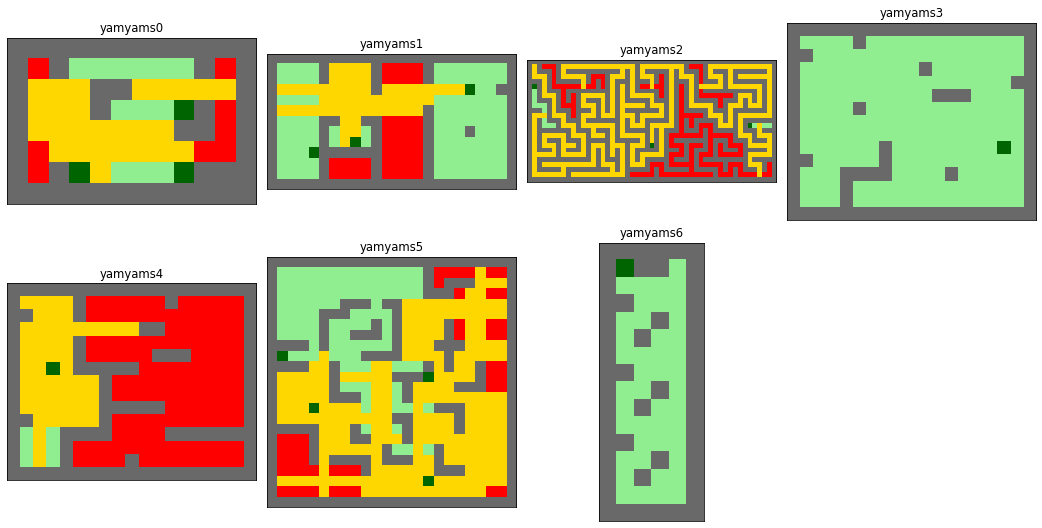

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

FARBEN = ListedColormap(['dimgray', 'red', 'gold', 'lightgreen', 'darkgreen'])   # Farbnummern 0 bis 4


def zeichne(achse, welt, rot, gelb, titel):
    bild = []
    for z in range(len(welt)):
        zeile = []
        for s in range(len(welt[z])):
            if welt[z][s] == '#':
                zeile.append(0)
            elif welt[z][s] == 'E':
                zeile.append(4)
            elif (z, s) in rot:
                zeile.append(1)
            elif (z, s) in gelb:
                zeile.append(2)
            else:
                zeile.append(3)             # grün = sicher
        bild.append(zeile)
    achse.imshow(bild, cmap=FARBEN, vmin=0, vmax=4)
    achse.set_title(titel)
    achse.set_xticks([])
    achse.set_yticks([])


fig, achsen = plt.subplots(2, 4, figsize=(15, 8))
achsen = list(achsen[0]) + list(achsen[1])
for i in range(len(NAMEN)):
    blau, rot, gelb, gruen = ergebnis[NAMEN[i]]
    zeichne(achsen[i], welten[NAMEN[i]], rot, gelb, NAMEN[i])
achsen[7].axis('off')
plt.tight_layout()
plt.show()

**Vergleich mit den Lösungshinweisen.** Abschnitt 3.6 der Hinweise zeigt für alle sieben Beispiele die sicheren Felder als Bild (dort ist
grün = sicher, alles andere weiß). Beim Erstellen dieses Notebooks haben wir diese Bilder Feld für Feld mit unserem Ergebnis verglichen:
**Bei allen sieben Welten stimmen die sicheren Felder genau überein.** Auch das Bild zu `yamyams6` in den Hinweisen passt zu unserer aus
dem PDF abgelesenen Welt.

In `yamyams1` liegt unten links ein abgeschlossener Raum (Zeilen 10 und 11, Spalten 6 bis 9) ohne Ausgang. Seine Felder sind rot,
obwohl kein anderes Feld sie erreicht. Die Lösungshinweise warnen, dass solche isolierten Bereiche manchen Programmen Probleme machen;
bei uns sind sie einfach Felder, von denen aus kein Ausgang erreichbar ist.

Die Lösungshinweise verlangen eine Ausgabe „ähnlich zur Eingabe in Textform“. Hier ist sie für die große Welt vom Aufgabenblatt:

In [ ]:
blau, rot, gelb, gruen = ergebnis['yamyams5']
print(als_text(welten['yamyams5'], markiere(gruen, 'S')))

########################
#SSSSSSSSSSSSSS#       #
#SSSSSSSSSSSSSS# ###   #
#SSSSSSSSSSSSSS###     #
#SSSSSS###S##          #
#SSSS###SSSS#          #
#SSSS#SSSS#S#    #     #
#SSSS#SS###S#    #     #
####S#SSSSSS#   ###    #
#ESSS SSS####    #     #
####  #SSS  SSS# #  #  #
#     #     ###E    #  #
#     #SSS  S#    ###  #
#     ###S  S#         #
#   E    S  SS S###    #
#           ##    #    #
#####   #S  S#    #    #
#   #   ##   #         #
#   #      #SS S#      #
#   # #### ###  #      #
#        #      ###    #
#              E       #
#                      #
########################


## Schritt 7: Probe durch Simulation

Wir lassen viele Yamyams wirklich torkeln. `simuliere` macht höchstens `max_fahrten` zufällige Fahrten und meldet, ob der Yamyam dabei einen
Ausgang erreicht hat. Wir starten je 10.000 Yamyams auf einem grünen, einem gelben und einem roten Feld von `yamyams0`.

In [ ]:
import random


def simuliere(welt, ziele, start, zufall, max_fahrten):
    feld = start
    for fahrten in range(max_fahrten):
        if ist_ausgang(welt, feld):
            return True
        if len(ziele[feld]) == 0:           # eingemauert: kommt nie weg
            return False
        feld = zufall.choice(ziele[feld])
    return ist_ausgang(welt, feld)


zufall = random.Random(1)
for start in [(1, 3), (2, 3), (5, 1)]:
    angekommen = 0
    for versuch in range(10000):
        if simuliere(welt0, ziele0, start, zufall, 200):
            angekommen = angekommen + 1
    if start in gruen0:
        farbe = 'grün'
    elif start in gelb0:
        farbe = 'gelb'
    else:
        farbe = 'rot'
    print(f'Start {start} ({farbe}): {angekommen} von 10000 Yamyams angekommen')

Start (1, 3) (grün): 10000 von 10000 Yamyams angekommen
Start (2, 3) (gelb): 7467 von 10000 Yamyams angekommen
Start (5, 1) (rot): 0 von 10000 Yamyams angekommen


Vom grünen Feld kommen alle Yamyams an, vom roten keiner. Vom gelben Feld `(2, 3)` (direkt unter dem sicheren Feld `(1, 3)`) schaffen es
etwa drei Viertel: Nach oben und nach unten geht es sicher weiter, wer aber nach links fährt, landet auf `(2, 1)` und gerät von dort leicht
auf ein rotes Feld wie `(1, 1)`. Eine Simulation kann die sicheren Felder aber
nicht beweisen. Dass alle 10.000 ankommen, heißt nur, dass die Wahrscheinlichkeit wohl nahe bei 1 liegt. Dafür brauchen wir die
Überlegung aus Schritt 4.

## Für Neugierige

### Die genauen Wahrscheinlichkeiten

Die Lösungshinweise beginnen mit einem Gleichungssystem (Abschnitt 3.2). Sei p(A) die Wahrscheinlichkeit, von Feld A aus einen Ausgang
zu erreichen. Für einen Ausgang ist p = 1. Hat ein freies Feld A die Ziele Z₁, …, Zₖ, dann wählt der Yamyam jedes mit der
Wahrscheinlichkeit 1/k, also

p(A) = (p(Z₁) + … + p(Zₖ)) / k.

Für die roten Felder ist p = 0. Das schreiben wir als eigene Gleichung dazu, denn sonst hätte das System keine eindeutige Lösung (in einem
Kreis aus roten Feldern ist zum Beispiel jeder gleiche Wert für alle eine Lösung; die Hinweise lösen das im Gauß-Verfahren mit einer
Sonderregel). Jedes Feld bekommt eine Nummer i, und `numpy.linalg.solve(A, b)` löst das System A · p = b.

In [ ]:
import numpy as np


def wahrscheinlichkeiten(welt):
    ziele = ziele_berechnen(welt)
    blau, rot, gelb, gruen, besucht = faerben(welt)
    felder = list(ziele)
    nummer = {}
    for i in range(len(felder)):
        nummer[felder[i]] = i
    n = len(felder)
    A = np.zeros((n, n))
    b = np.zeros(n)
    for feld in felder:
        i = nummer[feld]
        A[i, i] = 1
        if ist_ausgang(welt, feld):
            b[i] = 1                        # p = 1
        elif feld not in rot:               # p - (Summe der p der Ziele) / k = 0
            k = len(ziele[feld])
            for ziel in ziele[feld]:
                A[i, nummer[ziel]] = A[i, nummer[ziel]] - 1 / k
                                            # rote Felder: nur A[i, i] = 1 und b[i] = 0, also p = 0
    p = np.linalg.solve(A, b)
    ergebnis_p = {}
    for feld in felder:
        ergebnis_p[feld] = p[nummer[feld]]
    return ergebnis_p


p0 = wahrscheinlichkeiten(welt0)
markierung = {}
for feld in p0:
    markierung[feld] = f'{round(100 * p0[feld]):4}'
for z in range(len(welt0)):                 # Mauern und Ausgänge vierstellig, damit die Spalten passen
    zeile = ''
    for s in range(len(welt0[z])):
        if welt0[z][s] == ' ':
            zeile = zeile + markierung[(z, s)]
        else:
            zeile = zeile + '   ' + welt0[z][s]
    print(zeile)

   #   #   #   #   #   #   #   #   #   #   #   #
   #   0   # 100 100 100 100 100 100   #   0   #
   #  25  38  75   #   #  75  75  75  50  25   #
   #  25  38  75   # 100 100 100   E   #   0   #
   #  25  38  75  62  75  75  75   #   #   0   #
   #   0  12  50  38  50  50  50  33   0   0   #
   #   0   #   E  88 100 100 100   E   #   #   #
   #   #   #   #   #   #   #   #   #   #   #   #


Die Zahlen sind Prozent. Die sicheren Felder haben 100, die roten 0, die gelben liegen dazwischen; das Feld `(2, 3)` hat 75 %, passend zur
Simulation in Schritt 7 (7.467 von 10.000). Nun für alle Welten: Wie weit liegen die sicheren Felder höchstens von 1 entfernt, und wie groß ist die höchste
Wahrscheinlichkeit eines gelben Feldes?

In [ ]:
alle_p = {}
for name in NAMEN:
    p = wahrscheinlichkeiten(welten[name])
    alle_p[name] = p
    blau, rot, gelb, gruen = ergebnis[name]
    abstand_gruen = 0
    for feld in gruen:
        abstand_gruen = max(abstand_gruen, abs(1 - p[feld]))
    hoechstes_gelb = 0
    for feld in gelb:
        hoechstes_gelb = max(hoechstes_gelb, p[feld])
    if len(gelb) == 0:
        text_gelb = 'keine gelben Felder'
    else:
        text_gelb = f'gelb höchstens {hoechstes_gelb:.4f}'
    print(f'{name}: grün höchstens {abstand_gruen:.0e} von 1 entfernt, {text_gelb}')

yamyams0: grün höchstens 1e-16 von 1 entfernt, gelb höchstens 0.8750
yamyams1: grün höchstens 4e-16 von 1 entfernt, gelb höchstens 0.9167
yamyams2: grün höchstens 4e-16 von 1 entfernt, gelb höchstens 0.9375
yamyams3: grün höchstens 1e-14 von 1 entfernt, keine gelben Felder
yamyams4: grün höchstens 1e-16 von 1 entfernt, gelb höchstens 0.9286
yamyams5: grün höchstens 1e-15 von 1 entfernt, gelb höchstens 0.9687
yamyams6: grün höchstens 3e-14 von 1 entfernt, keine gelben Felder


Auf den grünen Feldern ist p bis auf Rundungsfehler der Kommazahlen (höchstens etwa 10⁻¹⁴) genau 1, auf den gelben Feldern deutlich kleiner
(höchstens etwa 0,97, bei `yamyams3` und `yamyams6` gibt es keine gelben Felder). Man könnte die sicheren Felder also auch über das
Gleichungssystem finden. Dazu muss man aber Kommazahlen mit einer Toleranz vergleichen und vorher die roten Felder kennen; das
Gleichungssystem ist außerdem viel aufwendiger (Gauß-Verfahren: etwa N³ Rechenschritte). Dafür bekommt man die genauen
Wahrscheinlichkeiten. Die Lösungshinweise zeigen sie als „Wahrscheinlichkeitskarte“, so wie hier (je dunkler, desto wahrscheinlicher kommt
der Yamyam an, Mauern schwarz):

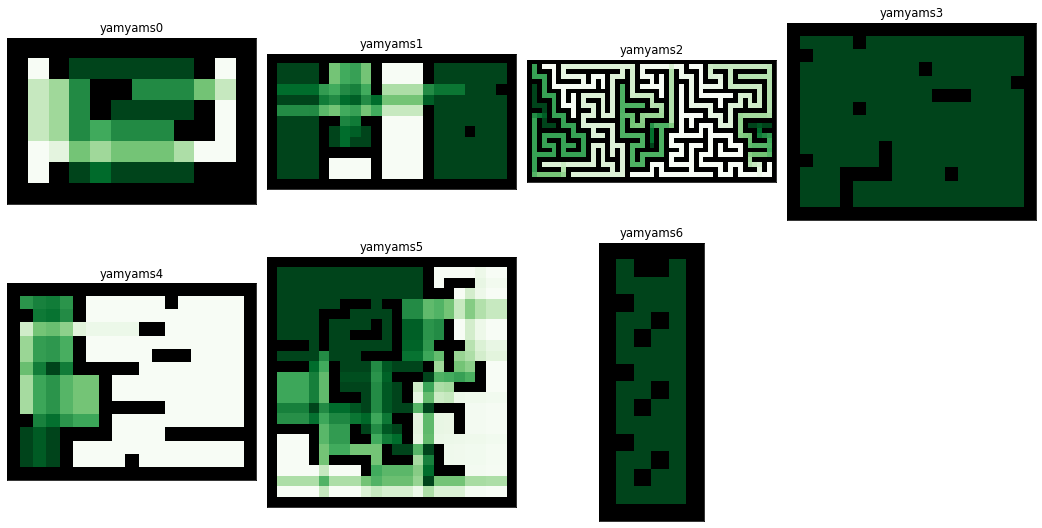

In [ ]:
fig, achsen = plt.subplots(2, 4, figsize=(15, 8))
achsen = list(achsen[0]) + list(achsen[1])
for i in range(len(NAMEN)):
    welt = welten[NAMEN[i]]
    p = alle_p[NAMEN[i]]
    karte = []
    for z in range(len(welt)):
        zeile = []
        for s in range(len(welt[z])):
            if welt[z][s] == '#':
                zeile.append(np.nan)        # nan = keine Zahl, wird nicht eingefärbt
            else:
                zeile.append(p[(z, s)])
        karte.append(zeile)
    achsen[i].set_facecolor('black')        # was nicht eingefärbt wird, ist schwarz
    achsen[i].imshow(karte, cmap='Greens', vmin=0, vmax=1)
    achsen[i].set_title(NAMEN[i])
    achsen[i].set_xticks([])
    achsen[i].set_yticks([])
achsen[7].axis('off')
plt.tight_layout()
plt.show()

### Wie viel Arbeit ist das? Große Zufallswelten

Beide Versionen berechnen zuerst alle Fahrten. Eine Fahrt geht über höchstens max(Breite, Höhe) Felder, das sind bei einer Welt aus
B × H Feldern zusammen höchstens etwa 4 · B · H · max(B, H) Schritte. Das ist die Laufzeit O(m · n · max(m, n)), die die Lösungshinweise
für ihr Flood-Fill-Verfahren angeben (sie warnen ausdrücklich davor, sie „linear“ zu nennen). Danach besucht Version 2 jedes Feld höchstens
zweimal, Version 1 dagegen von jedem der N Felder aus bis zu N Felder.

Wir erzeugen zufällige Welten: ringsum Mauern, innen jedes Feld mit 25 % Wahrscheinlichkeit eine Mauer, dazu Breite / 5 Ausgänge.
`len(gruen) - anzahl` zählt die sicheren freien Felder ohne die Ausgänge.

In [ ]:
def zufallswelt(breite, hoehe, anteil_mauern, anzahl_ausgaenge, saat):
    zufall = random.Random(saat)
    zeilen = []
    for z in range(hoehe):
        zeile = []
        for s in range(breite):
            if z == 0 or z == hoehe - 1 or s == 0 or s == breite - 1 or zufall.random() < anteil_mauern:
                zeile.append('#')
            else:
                zeile.append(' ')
        zeilen.append(zeile)
    gesetzt = 0
    while gesetzt < anzahl_ausgaenge:
        z = zufall.randrange(1, hoehe - 1)
        s = zufall.randrange(1, breite - 1)
        if zeilen[z][s] == ' ':
            zeilen[z][s] = 'E'
            gesetzt = gesetzt + 1
    welt = []
    for zeile in zeilen:
        welt.append(''.join(zeile))
    return welt


zufall_welten = {}
for groesse in [20, 40, 200]:
    anzahl = groesse // 5
    welt = zufallswelt(groesse, groesse, 0.25, anzahl, groesse)
    zufall_welten[groesse] = welt
    blau, rot, gelb, gruen, besucht2 = faerben(welt)
    text = f'{groesse:3} x {groesse:3}: {len(blau) + len(rot) - anzahl:5} freie Felder, davon {len(gruen) - anzahl:5} sicher; besucht V2 {besucht2:5}'
    if groesse <= 40:
        sicher, rot1, besucht1 = sichere_felder_v1(welt)
        text = text + f', V1 {besucht1:7} (gleich: {sicher == gruen})'
    print(text)
print()
blau, rot, gelb, gruen, besucht2 = faerben(zufall_welten[20])
print(als_text(zufall_welten[20], markiere(gruen, 'S')))

 20 x  20:   230 freie Felder, davon   186 sicher; besucht V2   237, V1    5583 (gleich: True)
 40 x  40:  1051 freie Felder, davon   284 sicher; besucht V2  1776, V1  227110 (gleich: True)
200 x 200: 29288 freie Felder, davon    65 sicher; besucht V2 57827

####################
#SSSSSSSSS#  #   # #
#ESSSSS#S###   ### #
#S###SS#SSS#   #   #
#SSS#SSSSS#S#      #
##S#SS#S#S#SS### ###
#SS#S#ES###SSSSS## #
#SSSSSSS#SSSSESS#S##
#SSESSSS#SS#S#SSSSS#
#SS#SSSSSSSS#SSSSSS#
#####S####S#SS##S#S#
#SSSSSSSS#SS#SSSS S#
#SSSSSSSSSSS#SSS# ##
#SSSS#SSS#S# ###   #
#SS#SSSSSSSS## # # #
#SS##SSSS#SSSS# #  #
##SSSSS##SS#SSS##  #
#SS#SSS#SSS#SS#    #
##SSSSSSSSSSSSS# # #
####################


Version 1 besucht bei der 40 × 40-Welt schon 227.110 Felder, Version 2 nur 1.776. Eine 200 × 200-Welt ist für Version 2 kein Problem;
Version 1 würde dort bis zu etwa 29.000 · 29.000, also über 800 Millionen Felder besuchen.

Auffällig: Je größer die Welt, desto kleiner der Anteil der sicheren Felder (186 von 230, 284 von 1.051, 65 von 29.288), obwohl es
im Verhältnis gleich viele Mauern und Ausgänge gibt. Ein einziges rotes Feld macht alle Felder unsicher, von denen aus der Yamyam es
erreichen kann, und in einer großen Welt gibt es fast immer irgendwo eine solche Falle.

### Ideen zum Weiterdenken (aus den Lösungshinweisen)

- **Dreidimensionale Welten:** Mit sechs Richtungen funktioniert alles genauso.
- **Mehrere Yamyams**, die sich gegenseitig im Weg stehen: Dann hängt eine Fahrt von den anderen ab, und die Rechnung wird sehr kompliziert.
- **Iteratives Verfahren:** Alle p erst auf 0 (Ausgänge 1) setzen und immer wieder durch den Durchschnitt der Ziele ersetzen. Das nähert
  sich den Wahrscheinlichkeiten nur an; ob ein Feld genau 1 hat, sieht man so nicht.

## Zum Schluss: Torkelnde Yamyams mit MiniZinc

Kann man die sicheren Felder auch mit MiniZinc bestimmen? Eine Suche nach „allem, was erreichbar ist“, lässt sich nicht direkt als
Bedingung hinschreiben. Wir nehmen stattdessen **Abstände**: `d1[i]` ist die kleinste Zahl von Fahrten, mit der man von Feld i aus einen
Ausgang erreicht. Für einen Ausgang ist sie 0, für jedes andere Feld 1 + der kleinste Abstand seiner Ziele. Ist kein Ausgang erreichbar,
setzen wir den Wert n (mehr als n − 1 Fahrten braucht man nie). Rot sind genau die Felder mit `d1[i] = n`. Ebenso ist `d2[i]` der
Abstand zum nächsten roten Feld; sicher sind die Felder mit `d2[i] = n`.

Die Gleichungen haben genau **eine** Lösung, nämlich die richtigen Abstände: Ist `d1[i] < n`, dann gibt es ein Ziel mit einem um 1
kleineren Wert, von dort wieder eines und so weiter, bis zu einem Feld mit dem Wert 0, einem Ausgang. Also gibt es wirklich einen Weg
mit `d1[i]` Fahrten. Umgekehrt kann `d1[i]` nicht größer sein als die Länge eines solchen Weges. MiniZinc muss also nichts optimieren,
nur die eine Lösung finden (`solve satisfy`).

Die Fahrten selbst rechnet Python aus (`ziele_berechnen`); MiniZinc bekommt die Ziele als Tabelle `nach`. Neu gegenüber den
Arbeitsblättern:
- `min(n, …)` ist das Minimum zweier Zahlen, `min(j in 1..anzahl[i])(…)` das Minimum über alle Fahrten eines Feldes.
- `if … then … elseif … else … endif` innerhalb einer Bedingung.
- Die Ausgabe zeichnet die Welt wie `als_text`: Für jedes Feld der Karte ein Zeichen, am Ende jeder Zeile ein Zeilenumbruch.
```minizinc
int: hoehe;
int: breite;
int: n;                                       % Anzahl der Felder (frei oder Ausgang)
array[1..hoehe, 1..breite] of 0..n: karte;    % Nummer des Feldes, 0 = Mauer
array[1..n] of bool: ausgang;
array[1..n] of 0..4: anzahl;                  % Anzahl der Fahrten (Ausgang: 0)
array[1..n, 1..4] of 1..n: nach;              % Ziel der j-ten Fahrt (nur j <= anzahl[i] zählt)

array[1..n] of var 0..n: d1;                  % Fahrten bis zum nächsten Ausgang, n = unerreichbar
array[1..n] of var 0..n: d2;                  % Fahrten bis zum nächsten roten Feld, n = unerreichbar

constraint forall(i in 1..n)(                 % Abstand zu einem Ausgang
    if ausgang[i] then d1[i] = 0
    elseif anzahl[i] = 0 then d1[i] = n
    else d1[i] = min(n, 1 + min(j in 1..anzahl[i])(d1[nach[i, j]]))
    endif);

constraint forall(i in 1..n)(                 % Abstand zu einem roten Feld
    if d1[i] = n then d2[i] = 0               % rot: kein Ausgang erreichbar
    elseif anzahl[i] = 0 then d2[i] = n
    else d2[i] = min(n, 1 + min(j in 1..anzahl[i])(d2[nach[i, j]]))
    endif);

solve satisfy;

output [if karte[z, s] = 0 then "#"
        elseif ausgang[karte[z, s]] then "E"
        elseif fix(d2[karte[z, s]]) = n then "S"    % sicher: kein rotes Feld erreichbar
        else " " endif
        ++ if s = breite then "\n" else "" endif
        | z in 1..hoehe, s in 1..breite];
```

Die Datendatei schreibt die Funktion `als_dzn`. Felder mit weniger als vier Fahrten füllen wir in der Tabelle `nach` mit 1 auf; diese
Einträge werden wegen `j in 1..anzahl[i]` nie benutzt.

In [ ]:
def als_dzn(welt):
    ziele = ziele_berechnen(welt)
    felder = list(ziele)
    nummer = {}
    for i in range(len(felder)):
        nummer[felder[i]] = i + 1           # MiniZinc zählt ab 1
    karte_zeilen = []
    for z in range(len(welt)):
        werte = []
        for s in range(len(welt[z])):
            werte.append(str(nummer.get((z, s), 0)))
        karte_zeilen.append(', '.join(werte))
    ausgang = []
    anzahl = []
    nach_zeilen = []
    for feld in felder:
        ausgang.append(str(ist_ausgang(welt, feld)).lower())
        anzahl.append(str(len(ziele[feld])))
        werte = []
        for ziel in ziele[feld]:
            werte.append(str(nummer[ziel]))
        while len(werte) < 4:
            werte.append('1')               # unbenutzte Plätze
        nach_zeilen.append(', '.join(werte))
    return (f'hoehe = {len(welt)};\nbreite = {len(welt[0])};\nn = {len(felder)};\n'
            f'karte = [| ' + ' |\n         '.join(karte_zeilen) + ' |];\n'
            f'ausgang = [{", ".join(ausgang)}];\nanzahl = [{", ".join(anzahl)}];\n'
            f'nach = [| ' + ' | '.join(nach_zeilen) + ' |];')


print(als_dzn(welten['yamyams0'])[:600], '...')

hoehe = 8;
breite = 12;
n = 49;
karte = [| 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0 |
         0, 1, 0, 2, 3, 4, 5, 6, 7, 0, 8, 0 |
         0, 9, 10, 11, 0, 0, 12, 13, 14, 15, 16, 0 |
         0, 17, 18, 19, 0, 20, 21, 22, 23, 0, 24, 0 |
         0, 25, 26, 27, 28, 29, 30, 31, 0, 0, 32, 0 |
         0, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 0 |
         0, 43, 0, 44, 45, 46, 47, 48, 49, 0, 0, 0 |
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0 |];
ausgang = [false, false, false, false, false, false, false, false, false, false, false, false, false, false, false, false, false, false, false, false, false ...


**Ausgabe von Gecode für `yamyams0`:**

**Ausgabe:**

```
############
# #SSSSSS# #
#   ##     #
#   #SSSE# #
#       ## #
#          #
# #E SSSE###
############
----------
```

Das ist dieselbe Karte wie in Schritt 4. Auch bei den anderen sechs Welten stimmt die Karte von MiniZinc Zeichen für Zeichen mit
`als_text` überein.

**Laufzeit.** Beim Erstellen dieses Notebooks haben wir alle sieben Welten mit mehreren Solvern gerechnet:
- **Gecode** ist bei jeder Welt in unter einer Sekunde fertig. Es muss gar nicht suchen (die Statistik meldet einen einzigen Knoten): Allein das Weiterreichen der Bedingungen (aus
  „ein Ziel hat Abstand 3“ folgt „ich habe höchstens Abstand 4“ usw.) legt alle Abstände fest.
- **CP-SAT** braucht bis zu etwa 4 Sekunden, **Chuffed** bis zu etwa 5 Sekunden (beide beim Labyrinth `yamyams2`).
- **HiGHS** braucht bis zu etwa 40 Sekunden (bei `yamyams3`), weil jedes `min` in viele ganzzahlige Hilfsbedingungen übersetzt wird.

Für einen LP-Löser wie HiGHS passt eine andere Formulierung besser: Maximiere die Summe aller `d1[i]` unter den Bedingungen `d1[i] <= d1[j] + 1`
für jede Fahrt von i nach j, `d1[i] = 0` für die Ausgänge und `d1[i] <= n`. Die größte Lösung sind genau die Abstände. So (zweimal
hintereinander, erst für die Ausgänge, dann für die roten Felder) schafft HiGHS jede Welt in unter einer Sekunde.

Für diese Aufgabe ist MiniZinc also möglich, aber kein Gewinn: Die zwei Rückwärtssuchen aus Version 2 sind kürzer, schneller und leichter
zu verstehen.